# Dinámica inmobiliaria en el Eje Cafetero
## Parte II – Técnicas de limpieza de datos

- **Fuente:** base limpia oficial (`data/processed/compraventas_eje_cafetero_completo_limpio.csv`), con las banderas de calidad de la Parte I definidas en `src/igac_inmobiliario/cleaning.py`.
- **Criterio:** la Parte I marcó los problemas sin borrar registros. Este notebook decide qué hacer con cada uno según lo que necesitan el índice de ventas repetidas y el modelo de alertas.
- **Principio:** ningún registro sale de la base. Las exclusiones se aplican a usos concretos (universo modelado y base del índice) y cada registro conserva sus banderas, de modo que cualquier decisión se puede revertir.
- **Estructura (guía):** 2.1 causas que hacen necesaria la limpieza (a. rangos válidos, b. vacíos y tipos, c. valores extremos, d. interrelaciones que no deberían existir); 2.2 soluciones evaluadas (eliminación general, imputación por regresión, imputación aleatoria) y decisión; 2.3 resultados.

In [1]:
# Configuración y carga
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid")

# Ubicar la raíz del repo (la carpeta que contiene src/)
RAIZ = Path.cwd()
while not (RAIZ / "src").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))
from src.igac_inmobiliario.fuentes_complementarias import cargar_ipc

d = pd.read_csv(RAIZ / "data/processed/compraventas_eje_cafetero_completo_limpio.csv", dtype=str)
banderas = [c for c in d.columns if d[c].isin(["True", "False"]).all()]
d[banderas] = d[banderas].eq("True")
for c in ["valor", "count_a", "count_de", "tiene_valor", "tiene_mas_de_un_valor", "rezago_escritura_anios"]:
    d[c] = pd.to_numeric(d[c])
d["year_radica"] = pd.to_numeric(d["year_radica"]).astype(int)
d["divipola"] = d["divipola"].str.zfill(5)
d["fecha_escritura"] = pd.to_datetime(d["fecha_escritura"])
d["anio_escritura"] = d["fecha_escritura"].dt.year
N = len(d)
print(f"Registros: {N:,} | Banderas de la Parte I: {len(banderas)}")

Registros: 457,558 | Banderas de la Parte I: 9


In [2]:
# Variables derivadas que usa esta parte (se calculan solo si la base procesada no las trae)
if "valor_simbolico_o_invalido" not in d:
    d["valor_simbolico_o_invalido"] = ~d["valor_valido"]
if "radicacion_antes_de_escritura" not in d:
    d["radicacion_antes_de_escritura"] = d["rezago_escritura_anios"] < 0
if "clave_escritura" not in d:
    # Misma regla de la Parte I: oficina + número de escritura + fecha de la escritura
    numero = pd.to_numeric(d["documento_justificativo"].str.extract(r"ESCRITURA\s+(\d+)")[0], errors="coerce")
    d["clave_escritura"] = (d["orip"] + "|" + numero.astype("Int64").astype(str) + "|"
                            + d["fecha_escritura"].dt.strftime("%Y-%m-%d")).where(numero.notna())
if "folios_en_escritura" not in d:
    d["folios_en_escritura"] = d["clave_escritura"].map(d.groupby("clave_escritura")["matricula"].nunique())

# La base procesada trae la fecha de radicación vacía en el 85%; en el CSV crudo está completa.
# Se toma del crudo (unida por pk) porque se necesita para corregir fechas imposibles.
ruta_crudo = RAIZ / "data/raw/compraventas_eje_cafetero_completo_crudo.csv"
if d["fecha_radica_texto"].isna().mean() > 0.01:
    crudo = pd.read_csv(ruta_crudo, dtype=str, usecols=["pk", "fecha_radica_texto"])
    d = d.drop(columns="fecha_radica_texto").merge(crudo, on="pk", how="left")
fr = d["fecha_radica_texto"]
d["fecha_radica"] = (pd.to_datetime(fr.str[:10], format="%Y-%m-%d", errors="coerce")
                     .fillna(pd.to_datetime(fr, format="%d/%m/%Y", errors="coerce"))
                     .fillna(pd.to_datetime(fr, format="%d/%m/%y", errors="coerce")))
print("Fecha de radicación interpretada:", f"{d['fecha_radica'].notna().mean():.2%}",
      "| coincide con year_radica:", f"{(d['fecha_radica'].dt.year == d['year_radica']).mean():.2%}")

# Fecha de análisis: la de la escritura, salvo en los 4.058 casos de orden imposible, donde se imputa
# la radicación menos el rezago mediano de su oficina (decisión justificada en la Prueba 3 de la sección 2.2)
U = d["incluido_universo_modelado"]
lag = (d["fecha_radica"] - d["fecha_escritura"]).dt.days
normal = U & d["rezago_escritura_anios"].between(0, 1) & lag.ge(0)
lag_orip = lag[normal].groupby(d.loc[normal, "orip"]).median()
imp = d["radicacion_antes_de_escritura"]
d["fecha_imputada"] = imp
d["fecha_analisis"] = d["fecha_escritura"]
d.loc[imp, "fecha_analisis"] = d.loc[imp, "fecha_radica"] - pd.to_timedelta(
    d.loc[imp, "orip"].map(lag_orip).fillna(lag[normal].median()), unit="D")

# Pesos constantes de 2023 (IPC del mes de la fecha de análisis)
ipc = cargar_ipc(RAIZ / "data/raw/fuentes/anex-IPC-Variacion-oct2026.xlsx")
ipc_2023 = ipc.loc[ipc["anio"] == 2023, "ipc"].mean()
d["ipc"] = pd.MultiIndex.from_arrays([d["fecha_analisis"].dt.year, d["fecha_analisis"].dt.month]).map(ipc.set_index(["anio", "mes"])["ipc"])
d["valor_2023"] = d["valor"] * ipc_2023 / d["ipc"]

Fecha de radicación interpretada: 100.00% | coincide con year_radica: 100.00%


## 2.1 Causas que hacen necesaria la limpieza

El registro del IGAC no es una encuesta: las "respuestas inválidas" son campos vacíos, valores fuera de rango o datos que se contradicen entre sí.

### a. Rangos válidos
Una compraventa debe tener valor positivo, una escritura anterior a su radicación y al menos un comprador y un vendedor.

In [3]:
rangos = pd.DataFrame([
    ("Valor vacío", d["valor"].isna().sum()),
    ("Valor en cero", d["valor"].eq(0).sum()),
    ("   de ellos con tiene_valor = 1", (d["valor"].eq(0) & d["tiene_valor"].eq(1)).sum()),
    ("Valor simbólico (≤ 100.000 pesos o < 1% de la mediana municipio-año)", d["valor_simbolico"].sum()),
    ("Escritura posterior a su radicación", d["radicacion_antes_de_escritura"].sum()),
    ("Sin comprador (count_a = 0)", d["count_a"].eq(0).sum()),
    ("Sin vendedor (count_de = 0)", d["count_de"].eq(0).sum()),
    ("   sin comprador, en la oficina de Manizales (100)", (d["count_a"].eq(0) & d["orip"].eq("100")).sum()),
    ("Anotación con más de un valor", d["tiene_mas_de_un_valor"].eq(1).sum()),
], columns=["problema", "registros"])
rangos["% del universo"] = rangos["registros"] / N * 100
display(rangos)

,problema,registros,% del universo
0,Valor vacío,15527,3.39
1,Valor en cero,520,0.11
2,de ellos con tiene_valor = 1,520,0.11
3,Valor simbólico (≤ 100.000 pesos o < 1% de la ...,616,0.13
4,Escritura posterior a su radicación,4058,0.89
5,Sin comprador (count_a = 0),2370,0.52
6,Sin vendedor (count_de = 0),2386,0.52
7,"sin comprador, en la oficina de Manizales (...",1700,0.37
8,Anotación con más de un valor,25,0.01


### b. Vacíos y tipos de dato
Los vacíos se miden sobre el CSV crudo de la fuente; el formato se refiere a cómo vienen escritos los campos.

In [4]:
crudo_completo = pd.read_csv(ruta_crudo, dtype=str)
vacios = crudo_completo.isna().mean().mul(100).sort_values(ascending=False)
display(vacios[vacios > 0].round(2).to_frame("% vacíos"))

print("Formatos de la fecha de radicación (texto):")
display(crudo_completo["fecha_radica_texto"].str.replace(r"\d", "9", regex=True).value_counts().to_frame("registros"))

tipo_doc = d["documento_justificativo"].str.extract(r"^\d{2}-\s*([A-ZÁÉÍÓÚÑ]+)")[0]
print("Tipo de documento justificativo:", tipo_doc.value_counts().head(6).to_dict())
print(f"Registros sin número de escritura legible (no se pueden agrupar en paquetes): {d['clave_escritura'].isna().sum():,}")

,% vacíos
folios_derivados,99.99
fecha_apertura_texto,76.88
estado_folio,5.07
valor,3.39


Formatos de la fecha de radicación (texto):


,registros
fecha_radica_texto,
9999-99-99 99:99:99,196786
99/99/9999,178155
99/99/99,82617


Tipo de documento justificativo: {'ESCRITURA': 457209, 'CERTIFICADO': 143, 'OFICIO': 90, 'RESOLUCION': 43, 'DOCUMENTO': 42, 'DEMANDA': 5}
Registros sin número de escritura legible (no se pueden agrupar en paquetes): 361


**El valor faltante no es aleatorio.** Se concentra en dos oficinas de registro, Calarcá (282) y La Dorada (106), que son el mismo lote sin estado del folio y con fecha en guiones que la Parte I asoció a un sistema de origen distinto.

Registros sin valor positivo: 16,047; de ellos en las oficinas 282 y 106: 15,406 (96.0%)
% sin valor en el lote sin estado del folio: 66.4%


,Calarcá y La Dorada (282 y 106),Otras 17 oficinas
year_radica,,
2015,100.00,0.20
2016,100.00,0.10
2017,100.00,0.20
2018,100.00,0.20
2019,100.00,0.10
2020,100.00,0.20
2021,37.70,0.10
2022,0.20,0.10
2023,0.20,0.10


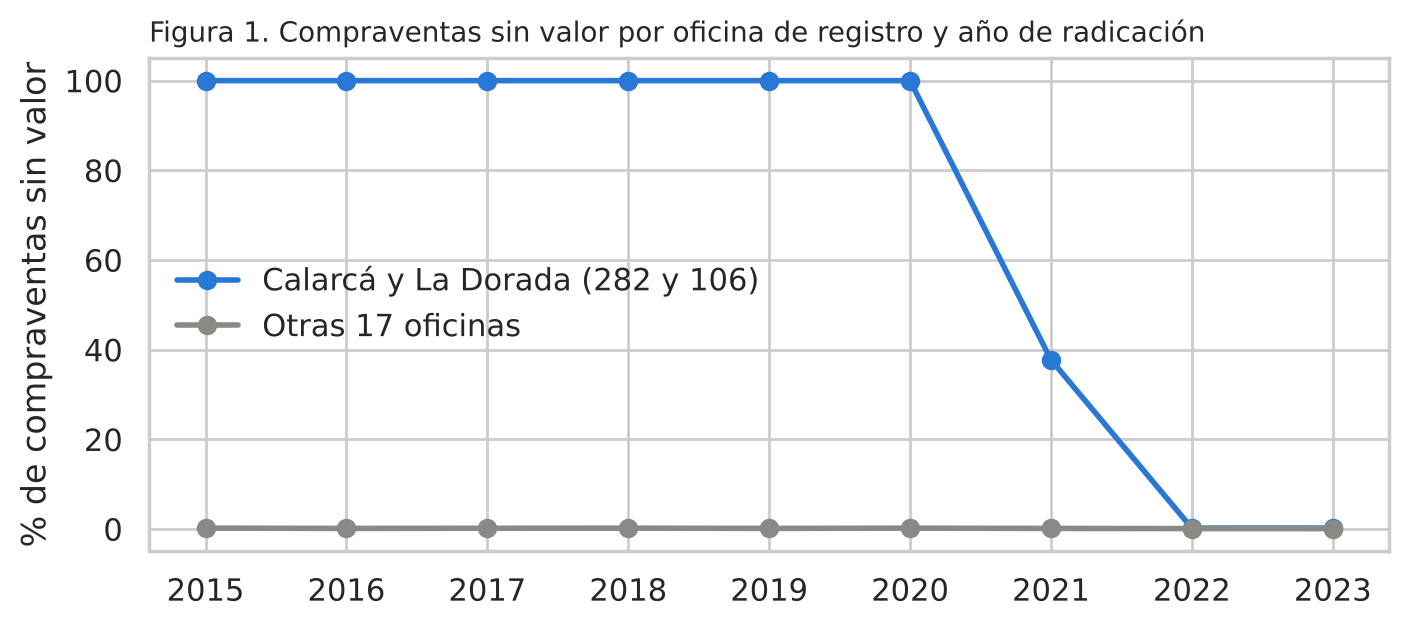

Municipios con más de la mitad de sus compraventas sin valor (22,929 registros):


,% sin valor
municipio,
CÓRDOBA,72.70
GÉNOVA,72.30
PIJAO,71.20
BUENAVISTA,68.80
CALARCÁ,67.50
VICTORIA,66.10
LA DORADA,64.50
NORCASIA,58.20


In [5]:
dos_orip = d["orip"].isin(["282", "106"])
sv = d["valor_simbolico_o_invalido"]
print(f"Registros sin valor positivo: {sv.sum():,}; de ellos en las oficinas 282 y 106: {(sv & dos_orip).sum():,} ({(sv & dos_orip).sum() / sv.sum():.1%})")
print(f"% sin valor en el lote sin estado del folio: {sv[d['estado_folio'].isna()].mean():.1%}")

grupo = np.where(dos_orip, "Calarcá y La Dorada (282 y 106)", "Otras 17 oficinas")
por_anio = d.groupby([grupo, "year_radica"])["valor_simbolico_o_invalido"].mean().unstack(0) * 100
display(por_anio.round(1))

fig, ax = plt.subplots(figsize=(8, 3.2))
for col, color in zip(por_anio.columns, ["#2a78d6", "#8a8984"]):
    ax.plot(por_anio.index, por_anio[col], marker="o", lw=2, color=color, label=col)
ax.set_ylabel("% de compraventas sin valor")
ax.set_title("Figura 1. Compraventas sin valor por oficina de registro y año de radicación", loc="left", fontsize=10)
ax.legend(frameon=False)
plt.show()

mun_sv = d.groupby("municipio")["valor_simbolico_o_invalido"].mean().mul(100)
municipios_limitados = mun_sv[mun_sv > 50].sort_values(ascending=False)
print(f"Municipios con más de la mitad de sus compraventas sin valor ({d['municipio'].isin(municipios_limitados.index).sum():,} registros):")
display(municipios_limitados.round(1).to_frame("% sin valor"))

### c. Valores extremos
Puntaje robusto: distancia del logaritmo del valor (pesos de 2023) a la mediana de su municipio, año y zona, dividida por la desviación absoluta mediana. Se marca como extremo si supera 3,5 en valor absoluto (Iglewicz y Hoaglin). Solo se calcula en grupos con 30 registros o más.

In [6]:
u = d[U].copy()
u["log_valor_2023"] = np.log(u["valor_2023"])
g = u.groupby(["divipola", "anio_escritura", "tipo_predio_zona"])["log_valor_2023"]
med = g.transform("median")
mad = g.transform(lambda s: (s - s.median()).abs().median())
u["z_nivel"] = (0.6745 * (u["log_valor_2023"] - med) / mad).where(g.transform("size") >= 30)
d["z_nivel"] = u["z_nivel"]
d["extremo_alto"] = d["z_nivel"] > 3.5
d["extremo_bajo"] = d["z_nivel"] < -3.5

display(pd.DataFrame({
    "registros": [d["extremo_alto"].sum(), (d["extremo_alto"] & d["escritura_paquete"]).sum(), d["extremo_bajo"].sum(),
                  (U & d["z_nivel"].isna()).sum(), (U & d["valor"].gt(1e10)).sum(), (U & d["valor"].gt(1e10) & d["escritura_paquete"]).sum()]},
    index=["Extremo alto", "   de ellos en escritura paquete", "Extremo bajo", "Sin puntaje (grupo < 30)",
           "Valor > 10.000 millones", "   de ellos totales de paquete"]))
print(f"Valor máximo: {d.loc[U, 'valor'].max() / 1e6:,.0f} millones")
display(d[U].nlargest(5, "valor")[["municipio", "tipo_predio_zona", "valor", "folios_en_escritura", "valor_repetido_en_paquete"]])

,registros
Extremo alto,1953
de ellos en escritura paquete,1337
Extremo bajo,10137
Sin puntaje (grupo < 30),4954
Valor > 10.000 millones,457
de ellos totales de paquete,427


Valor máximo: 820,000 millones


,municipio,tipo_predio_zona,valor,folios_en_escritura,valor_repetido_en_paquete
316215,PEREIRA,RURAL,"820,000,000,000.00",1.00,False
83377,ARANZAZU,URBANO,"495,179,989,000.00",12.00,True
83378,ARANZAZU,URBANO,"495,179,989,000.00",12.00,True
83382,ARANZAZU,URBANO,"495,179,989,000.00",12.00,True
83383,ARANZAZU,URBANO,"495,179,989,000.00",12.00,True


### d. Interrelaciones que no deberían existir

In [7]:
fa = pd.to_datetime(d["fecha_apertura_texto"].str[:10], format="%Y-%m-%d", errors="coerce")
inter = pd.DataFrame([
    ("El valor total de la escritura se repite en cada folio del paquete", d["valor_repetido_en_paquete"].sum()),
    ("La misma anotación aparece en dos años", d["anotacion_duplicada"].sum()),
    ("Escritura firmada dos o más años antes de registrarse", d["escritura_rezagada"].sum()),
    ("Estado del folio vacío (solo en las oficinas 282 y 106)", d["estado_folio"].isna().sum()),
    ("Apertura del folio posterior a la escritura", (fa > d["fecha_escritura"]).sum()),
], columns=["problema", "registros"])
display(inter)
print("Oficinas con estado del folio vacío:", d.loc[d["estado_folio"].isna(), "orip"].value_counts().to_dict())
print("El estado del folio describe el folio hoy (2025): es información posterior a la venta y delata el sistema de origen,"
      " así que no debe usarse como variable explicativa.")

,problema,registros
0,El valor total de la escritura se repite en ca...,97105
1,La misma anotación aparece en dos años,3254
2,Escritura firmada dos o más años antes de regi...,2835
3,Estado del folio vacío (solo en las oficinas 2...,23193
4,Apertura del folio posterior a la escritura,1958


Oficinas con estado del folio vacío: {'282': 12605, '106': 10588}
El estado del folio describe el folio hoy (2025): es información posterior a la venta y delata el sistema de origen, así que no debe usarse como variable explicativa.


## 2.2 Soluciones evaluadas y decisión

Antes de decidir, se prueban con los datos las alternativas para los cuatro problemas que no tienen una respuesta obvia.

### Prueba 1. ¿Se puede prorratear el valor de un paquete entre sus folios?
Se usan las escrituras paquete que sí informan un valor distinto por folio: se compara el valor real de cada folio con el total dividido por el número de folios.

In [8]:
pq = d[d["escritura_paquete"] & U & ~d["valor_repetido_en_paquete"]]
gp = pq.groupby("clave_escritura")
err = np.log(pq["valor"] / (gp["valor"].transform("sum") / gp["matricula"].transform("nunique")))
rp = d[d["valor_repetido_en_paquete"] & U]
print(f"Escrituras de prueba: {pq['clave_escritura'].nunique():,} ({len(pq):,} folios)")
print(f"Error mediano del prorrateo: {np.exp(np.median(np.abs(err))) - 1:.0%}")
print(f"Folios a menos del 20% de su valor real: {(np.abs(err) < np.log(1.2)).mean():.1%}")
print(f"Cuota mediana del folio principal en el total: {(gp['valor'].max() / gp['valor'].sum()).median():.0%}")
print(f"Paquetes con valor repetido que son escrituras de dos folios: {rp['folios_en_escritura'].eq(2).mean():.1%}")

Escrituras de prueba: 26,307 (63,232 folios)
Error mediano del prorrateo: 168%
Folios a menos del 20% de su valor real: 7.0%
Cuota mediana del folio principal en el total: 91%
Paquetes con valor repetido que son escrituras de dos folios: 58.5%


### Prueba 2. ¿La inflación explica el valor bajo de las escrituras rezagadas?

In [9]:
C0 = U & ~d["valor_repetido_en_paquete"] & ~d["escritura_rezagada"]
z = d[d["escritura_rezagada"] & d["valor_valido"] & ~d["anotacion_duplicada"] & d["ipc"].notna()]
tramos = pd.cut(z["rezago_escritura_anios"], [1, 2, 5, 10, 200], labels=["2 años", "3-5", "6-10", "11 o más"])
tab = z.groupby(tramos, observed=True)["valor_2023"].agg(["size", "median"])
tab["median"] /= 1e6
tab.columns = ["registros", "mediana (millones de 2023)"]
display(tab)
print(f"Mediana de las compraventas contemporáneas: {d.loc[C0, 'valor_2023'].median() / 1e6:,.1f} millones de 2023")

,registros,mediana (millones de 2023)
rezago_escritura_anios,,
2 años,862,62.66
3-5,771,32.29
6-10,413,22.18
11 o más,225,15.67


Mediana de las compraventas contemporáneas: 66.7 millones de 2023


### Prueba 3. ¿Qué patrón tienen las escrituras con fecha posterior a su radicación?

In [10]:
r = d[d["radicacion_antes_de_escritura"]]
formato_dd_mm_aa = d["documento_justificativo"].str.contains(r"DEL \d{1,2}/\d{1,2}/\d{2}\b")
print(f"Casos: {len(r):,}")
print(f"Usan el formato 'DEL dd/mm/aa': {formato_dd_mm_aa[r.index].mean():.1%} (en toda la base: {formato_dd_mm_aa.mean():.1%})")
print("Oficinas:", r["orip"].value_counts().head(4).to_dict())
print(f"Días mediana entre radicación y escritura citada: {(r['fecha_escritura'] - r['fecha_radica']).dt.days.median():.0f}")

print(f"Rezago normal escritura → radicación: mediana {lag[normal].median():.0f} días, percentil 90 {lag[normal].quantile(0.9):.0f} días")

Casos: 4,058
Usan el formato 'DEL dd/mm/aa': 100.0% (en toda la base: 18.1%)
Oficinas: {'100': 3018, '103': 240, '114': 158, '115': 152}
Días mediana entre radicación y escritura citada: 223
Rezago normal escritura → radicación: mediana 11 días, percentil 90 54 días


### Prueba 4. ¿Qué tan bien explicarían una imputación por regresión las variables disponibles?
Regresión del logaritmo del valor (pesos de 2023) sobre todas las variables de la base. Si el ajuste es bajo, un valor imputado sería poco más que la mediana del municipio.

In [11]:
from sklearn.linear_model import LinearRegression

base = d[C0 & d["tiene_mas_de_un_valor"].eq(0) & d["fecha_analisis"].dt.year.between(2015, 2023)].copy()
X = pd.get_dummies(base[["divipola", "tipo_predio_zona"]].assign(
    anio=base["fecha_analisis"].dt.year.astype(str), mes=base["fecha_analisis"].dt.month.astype(str),
    compradores=base["count_a"].clip(upper=3).astype(str), vendedores=base["count_de"].clip(upper=3).astype(str),
    folio_nuevo=base["predios_nuevos"].astype(str), paquete=base["escritura_paquete"].astype(str)), drop_first=True, dtype=float)
r2 = LinearRegression().fit(X, np.log(base["valor_2023"])).score(X, np.log(base["valor_2023"]))
print(f"R² con todas las variables disponibles: {r2:.1%}")

R² con todas las variables disponibles: 16.8%


### Decisión por problema (Tabla 7 del informe)

| Problema | Eliminación general | Imputación por regresión | Imputación aleatoria | Decisión |
|---|---|---|---|---|
| Valor vacío o en cero (16.047) | Como regla general no (los folios derivados faltan en el 99,99%); para el valor sí | No: el ajuste es bajo (prueba 4) e inventaría dos tercios del mercado de ocho municipios | No: añade ruido y crea alertas al azar | **Excluir del modelado, conservar en la base y marcar los ocho municipios con cobertura limitada** |
| Fecha posterior a la radicación (4.058) | Pierde el 0,9% de la base sin necesidad | **Sí, por patrón**: radicación menos el rezago mediano de su oficina (prueba 3) | No: el patrón es estable | **Imputar la fecha y conservar el valor** |
| Valor total repetido en paquete (97.105) | Sí, para el índice | Prorrateo descartado (prueba 1) | No aplica | **Excluir del índice; en las alertas, evaluar la escritura completa** |
| Escritura rezagada (2.835) | Sí, para el índice | Deflactar no basta (prueba 2) | No aplica | **Excluir del índice y conservar en la base** |
| Anotación duplicada (3.254) y valor simbólico (616) | Sí | No aplica | No aplica | **Eliminar del universo modelado** |
| Más de un valor (25) | Sí, para el índice | No hay patrón | No aplica | **Excluir del índice** |
| Valores extremos | No: son el objeto de las alertas | No aplica | No aplica | **Conservar y marcar; el índice se estima con la mediana** |
| Sin comprador o vendedor; apertura posterior | No | No aplica | No aplica | **Sin acción: campos no usados** |
| Estado del folio | No aplica | No aplica | No aplica | **Excluir como variable explicativa** |

In [12]:
# Imputación de la fecha (calculada en la celda de preparación): radicación menos el rezago mediano de su oficina
print("Rezago mediano por oficina usado (días):", lag_orip.astype(int).to_dict())
print(f"Fechas imputadas: {imp.sum():,}; todas quedan antes de su radicación: {(d.loc[imp, 'fecha_analisis'] <= d.loc[imp, 'fecha_radica']).all()}")

# Base del índice
d["base_indice"] = C0 & d["tiene_mas_de_un_valor"].eq(0)

Rezago mediano por oficina usado (días): {'100': 9, '102': 6, '103': 12, '106': 7, '108': 14, '110': 19, '112': 5, '114': 6, '115': 9, '118': 8, '280': 13, '282': 15, '284': 5, '290': 10, '292': 19, '293': 15, '294': 13, '296': 11, '297': 12}
Fechas imputadas: 4,058; todas quedan antes de su radicación: True


## 2.3 Resultados de la limpieza (Tabla 8 del informe)

In [13]:
embudo = pd.DataFrame([
    ("Universo de análisis (código 125)", N, ""),
    ("Con valor positivo", d["valor_valido"].sum(), "Sin valor (96% de dos oficinas)"),
    ("Universo modelado", U.sum(), "Duplicados y valores simbólicos"),
    ("Sin valor total repetido en paquete", (U & ~d["valor_repetido_en_paquete"]).sum(), "Folios con el total de la escritura"),
    ("Sin escrituras rezagadas", C0.sum(), "Valores de otra época"),
    ("Base del índice", d["base_indice"].sum(), "Anotaciones con más de un valor"),
], columns=["paso", "registros", "qué sale"])
embudo["% del universo"] = embudo["registros"] / N * 100
display(embudo)
print(f"Registros de la base del índice con fecha imputada: {(d['base_indice'] & d['fecha_imputada']).sum():,}")

,paso,registros,qué sale,% del universo
0,Universo de análisis (código 125),457558,,100.00
1,Con valor positivo,441511,Sin valor (96% de dos oficinas),96.49
2,Universo modelado,437648,Duplicados y valores simbólicos,95.65
3,Sin valor total repetido en paquete,340967,Folios con el total de la escritura,74.52
4,Sin escrituras rezagadas,338941,Valores de otra época,74.08
5,Base del índice,338927,Anotaciones con más de un valor,74.07


Registros de la base del índice con fecha imputada: 2,614


In [14]:
# Guardar las decisiones para la Parte III (una fila por registro, unida por pk)
salida = RAIZ / "data/processed/decisiones_limpieza_parte2.csv"
cols = ["pk", "fecha_analisis", "fecha_imputada", "valor_2023", "z_nivel", "extremo_alto", "extremo_bajo", "base_indice"]
d[cols].to_csv(salida, index=False)
print(f"Guardado: {salida.relative_to(RAIZ)} ({len(d):,} filas)")

Guardado: data/processed/decisiones_limpieza_parte2.csv (457,558 filas)


## Conclusiones de la Parte II

- **Solo se imputa la fecha**, en los 4.058 casos de orden imposible: el error tiene un patrón claro, la fecha de radicación está completa y el margen de error (días) es pequeño frente a la unidad del índice (años).
- **El valor no se imputa.** El faltante proviene de un sistema de origen (oficinas 282 y 106, 2015–2020), no del azar, y las variables disponibles explican poco del valor: imputarlo inventaría el mercado de ocho municipios y generaría referencias y alertas falsas.
- **Paquetes y rezagadas salen del índice, no de la base.** El prorrateo falla y el valor rezagado no se corrige deflactando.
- **Los extremos se conservan y se marcan**, porque son lo que el modelo de alertas debe encontrar. Para que no distorsionen el índice, este se estima con la mediana.
- **La base del índice conserva el 74,1% del universo**, y el universo modelado (95,6%) sigue disponible para las alertas.